# Q13 - P-Creativity as a Special Function of H-Creativity

Same code as `q13_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q13 - Psychological creativity (P) as a special case of historical creativity (H).

States are ideas = points in a 2-D conceptual space. novelty_H uses the archive of ALL human
history, novelty_P uses only the agent's own archive (a subset), so P = H restricted to what
the agent remembers. The search starts in a small, constrained circle around idea j, expands
it slowly, eliminates visited or weak states, and when the circle is empty it combines the
n best states into new ones. The centre then moves (j -> n -> i) and the loop repeats until
the combinations stop reaching beyond the space that is already covered.
"""
import math
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
rng = np.random.default_rng(13)

PEAKS = [((9.0, 9.0), 6.0, 0.45), ((9.0, 9.0), 2.4, 0.6), ((3.0, 8.0), 1.5, 0.55), ((8.5, 2.0), 1.5, 0.45)]
J = (2.0, 2.0)                       # idea j: where the agent starts
R0, DR, R_CAP = 1.0, 1.0, 3.0        # constrained circle, slow expansion, cap per stage
TAU_V, N_TOP, TAU_NOVEL, MAX_STAGES = 14.0, 4, 1.0, 8


def value(p: tuple) -> float:
    """Usefulness of an idea (0-100): three peaks, the tallest one is far from j."""
    return 100 * sum(h * math.exp(-((p[0] - c[0]) ** 2 + (p[1] - c[1]) ** 2) / (2 * s * s))
                     for c, s, h in PEAKS)


def dist(a: tuple, b: tuple) -> float:
    return math.hypot(a[0] - b[0], a[1] - b[1])


def novelty(p: tuple, archive: list) -> float:
    return min(dist(p, a) for a in archive)


HISTORY = [tuple(map(float, q)) for q in rng.uniform(0, 7, (36, 2)) if dist(q, (6, 6)) > 1.5]
AGENT = HISTORY[:7]                                       # agent remembers only a little
assert all(a in HISTORY for a in AGENT)                   # Archive_agent is a subset
POOL = [tuple(map(float, q)) for q in rng.uniform(0, 11.5, (260, 2))]


def blend(a: tuple, b: tuple) -> tuple:
    """Combine two states: a point on (or a little beyond) the line joining them."""
    t = rng.uniform(-0.2, 1.2)
    return (min(11.5, max(0.0, a[0] + t * (b[0] - a[0]) + rng.normal(0, 0.3))),
            min(11.5, max(0.0, a[1] + t * (b[1] - a[1]) + rng.normal(0, 0.3))))


def creative_search(pool: list, j: tuple):
    centre, visited, kept, discs, rows, path = j, set(), [], [], [], [j]
    for stage in range(1, MAX_STAGES + 1):
        r = R0
        while True:                                       # slow expansion of the search space
            space = [s for s in pool if s not in visited and dist(s, centre) <= r]
            low = [s for s in space if value(s) < TAU_V]                 # eliminate weak states
            kept += [s for s in space if value(s) >= TAU_V]
            visited |= set(space)                                        # eliminate visited ones
            rows.append([stage, r, len(space), len(space) - len(low), len(low), 0])
            if r >= R_CAP:
                break                                     # nothing left inside the cap: combine
            r += DR
        discs.append((centre, R_CAP))
        top = sorted(kept, key=value, reverse=True)[:N_TOP]
        new = [blend(a, b) for i, a in enumerate(top) for b in top[i + 1:]]
        beyond = [s for s in new if all(dist(s, c) > rad for c, rad in discs)]
        rows[-1][5] = len(new)
        pool += new
        if not beyond:                                    # no new state outside the covered space
            break
        centre = max(new, key=value)
        path.append(centre)
    return kept + pool[260:], rows, discs, path


final, rows, discs, path = creative_search(list(POOL), J)
print("Q13  P-creativity as a special case of H-creativity (2-D conceptual space)")
print(f"start idea j={J}, value {value(J):.0f}; archives: history {len(HISTORY)}, agent {len(AGENT)}")
print("stage radius examined kept eliminated created")
for st, r, ex, kp, el, cr in rows:
    print(f"  {st:>3}  {r:>5.1f}  {ex:>7} {kp:>4} {el:>10} {cr:>7}")
print(f"stopped after {len(discs)} stages; centre moved j -> "
      + " -> ".join(f"({p[0]:.1f},{p[1]:.1f})" for p in path[1:]))

ranked = sorted(set(final), key=value, reverse=True)[:8]
print("Top-ranked final set: value | novelty_P | novelty_H | P-creative | H-creative")
for p in ranked:
    npv, nhv = novelty(p, AGENT), novelty(p, HISTORY)
    print(f"  ({p[0]:4.1f},{p[1]:4.1f}) {value(p):5.1f} | {npv:5.2f} | {nhv:5.2f} | "
          f"{'yes' if npv >= TAU_NOVEL else 'no':>3} | {'yes' if nhv >= TAU_NOVEL else 'no':>3}")
allp = list(set(final))
p_set = {p for p in allp if novelty(p, AGENT) >= TAU_NOVEL}
h_set = {p for p in allp if novelty(p, HISTORY) >= TAU_NOVEL}
print(f"all {len(allp)} states: P-creative {len(p_set)}, H-creative {len(h_set)}, "
      f"H inside P: {h_set <= p_set}")

# ---------------- chart 1: Diagram-5 style ----------------
fig, ax = plt.subplots(figsize=(6.8, 6.4))
xs, ys = np.meshgrid(np.linspace(0, 11.5, 120), np.linspace(0, 11.5, 120))
zz = np.vectorize(lambda a, b: value((a, b)))(xs, ys)
ax.contourf(xs, ys, zz, levels=10, cmap="YlOrBr", alpha=0.35)
ax.scatter(*zip(*POOL), s=14, color="#9ca3af", label="candidate ideas")
ax.scatter(*zip(*HISTORY), s=26, color="#3a6ea5", marker="s", label="history archive")
ax.scatter(*zip(*AGENT), s=60, facecolors="none", edgecolors="#1e3a8a", lw=1.6,
           marker="s", label="agent archive")
for k, (c, r) in enumerate(discs):
    ax.add_patch(plt.Circle(c, r, fill=False, ec="#a0303a", lw=1.6, alpha=0.9))
    ax.text(c[0] - r * 0.7, c[1] + r * 0.82, f"stage {k + 1}", color="#a0303a", fontsize=8)
for a, b in zip(path[:-1], path[1:]):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="#2a9d8f", lw=2.2,
                                                    mutation_scale=16))
for tag, p in zip(["j"] + [f"n{k}" for k in range(1, len(path))], path):
    ax.scatter(*p, s=90, color="#2a9d8f", zorder=5)
    ax.text(p[0] + 0.15, p[1] - 0.55, tag, fontsize=10, fontweight="bold", color="#115e59")
ax.scatter(*zip(*ranked[:5]), s=110, marker="*", color="#d62828", zorder=6, label="top-ranked ideas")
ax.set_xlim(0, 11.5)
ax.set_ylim(0, 11.5)
ax.set_aspect("equal")
ax.set_title("Search space grows and moves: j -> n -> i", fontsize=10.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=3, fontsize=7.5, frameon=False)
fig.tight_layout()
fig.savefig("images/q13_chart1_diagram5_style.png")
plt.close(fig)

# ---------------- chart 2: counts per round ----------------
labels = [f"S{r[0]}\nr={r[1]:.0f}" for r in rows]
fig, ax = plt.subplots(figsize=(11, 3.9))
x = np.arange(len(rows))
ax.bar(x - 0.27, [r[2] for r in rows], 0.27, color="#9ca3af", label="states in space")
ax.bar(x, [r[3] for r in rows], 0.27, color="#2a9d8f", label=f"kept (value >= {TAU_V:.0f})")
ax.bar(x + 0.27, [r[5] for r in rows], 0.27, color="#e76f51", label="new states created")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("number of states")
ax.set_title("Per round: space is examined, weak states eliminated, top-n combined")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q13_chart2_rounds.png")
plt.close(fig)

# ---------------- chart 3: novelty P vs H ----------------
fig, ax = plt.subplots(figsize=(5.4, 4.6))
npv = [novelty(p, AGENT) for p in allp]
nhv = [novelty(p, HISTORY) for p in allp]
ax.scatter(npv, nhv, s=16, color="#3a6ea5", alpha=0.6)
ax.plot([0, max(npv)], [0, max(npv)], "--", color="#d62828", label="novelty_H = novelty_P")
ax.axhline(TAU_NOVEL, color="#6b7280", lw=0.8)
ax.axvline(TAU_NOVEL, color="#6b7280", lw=0.8)
ax.set_xlabel("novelty_P (own archive)")
ax.set_ylabel("novelty_H (history)")
ax.set_title("Every point lies on or below the diagonal:\nH-creative implies P-creative", fontsize=9.5)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q13_chart3_p_vs_h.png")
plt.close(fig)
print("charts saved to images/")


Q13  P-creativity as a special case of H-creativity (2-D conceptual space)
start idea j=(2.0, 2.0), value 12; archives: history 30, agent 7
stage radius examined kept eliminated created
    1    1.0        7    2          5       0
    1    2.0       22    6         16       0
    1    3.0       21   15          6       6
    2    1.0        5    5          0       0
    2    2.0       15   15          0       0
    2    3.0       26   26          0       6
    3    1.0        7    7          0       0
    3    2.0       13   13          0       0
    3    3.0       21   21          0       6
stopped after 3 stages; centre moved j -> (4.1,4.5) -> (3.4,7.9)
Top-ranked final set: value | novelty_P | novelty_H | P-creative | H-creative
  ( 3.3, 8.2)  85.3 |  2.76 |  1.76 | yes | yes
  ( 3.4, 7.9)  85.0 |  2.59 |  1.44 | yes | yes
  ( 3.0, 8.3)  83.5 |  2.81 |  2.01 | yes | yes
  ( 3.1, 8.4)  83.4 |  2.93 |  2.05 | yes | yes
  ( 3.8, 8.1)  83.1 |  3.03 |  1.60 | yes | yes
  ( 3.8, 8.2)  83

charts saved to images/


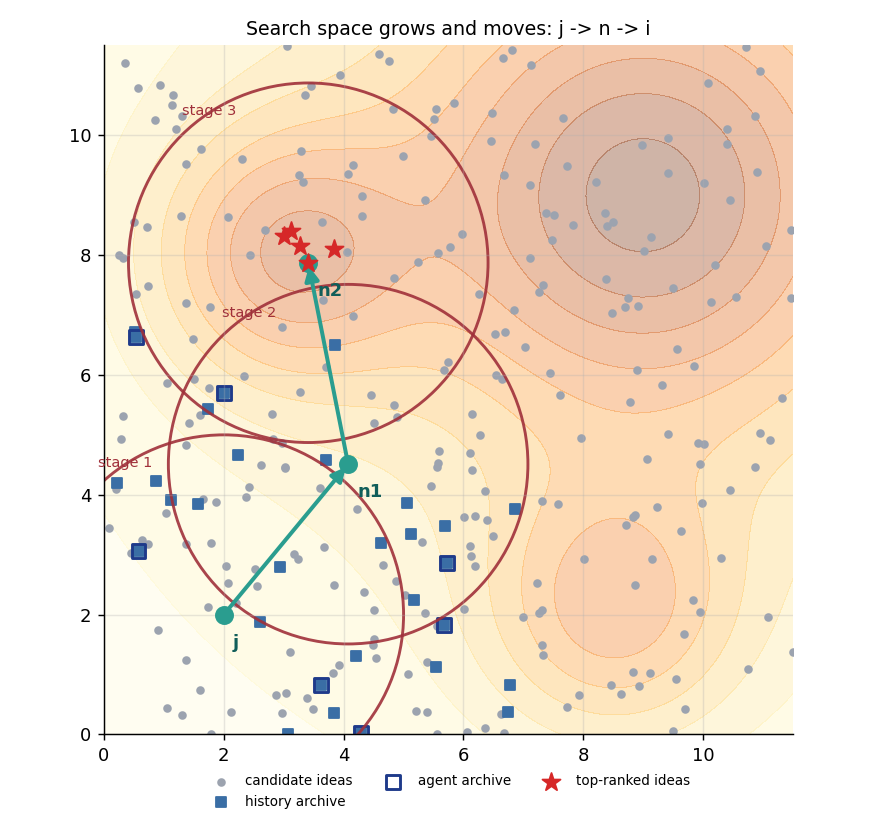

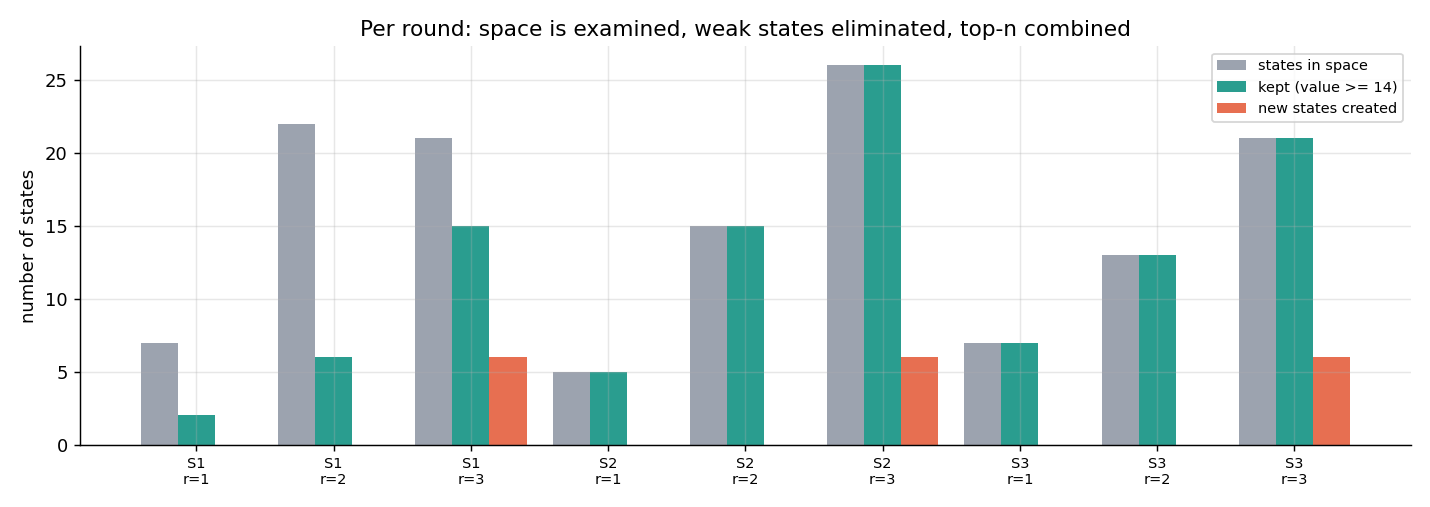

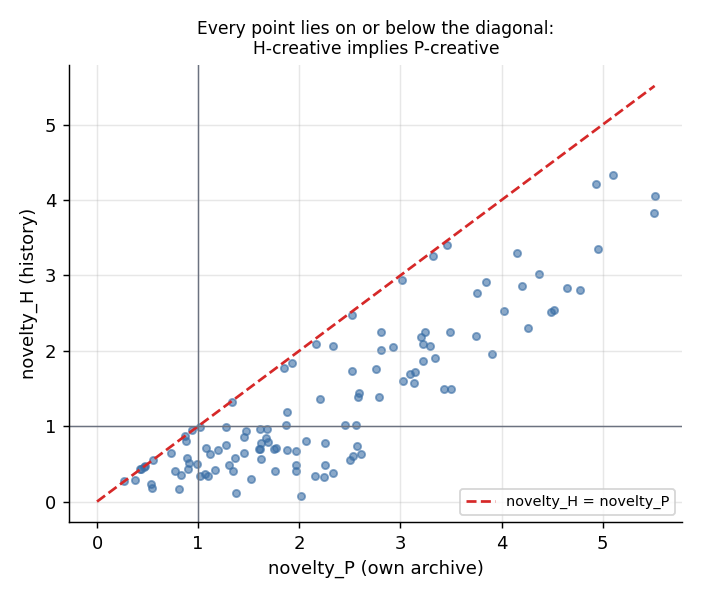

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q13_chart*.png')):
    display(Image(p))